# 🕷️ Spider-Man in tutti i media – Analisi dei dati

**Progetto personale di Francesco Autorino – Data Analyst**

🧭 **Domanda principale:** come è cresciuto Spider-Man passando dai fumetti a film, serie TV e videogiochi?

1. Quale media ha fatto guadagnare di più Spider-Man?
2. Come sono andati i film? Quale saga funziona meglio?
3. Film e videogiochi fanno cercare il fumetto?
4. Come è cambiato Spider-Man nei videogiochi?
5. Chi sono i personaggi più importanti del suo mondo?

🗂️ Dati: tabelle pulite in `02Dati/2Puliti` (script `01RaccoltaDati/02_pulizia.py`).

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
from scipy import stats

CLEAN = Path("../02Dati/2Puliti"); GRAFICI = Path("grafici"); GRAFICI.mkdir(exist_ok=True)
leggi = lambda n: pd.read_csv(CLEAN / f"{n}.csv")
film, giochi, serie, fum = leggi("film"), leggi("videogiochi"), leggi("serie_tv"), leggi("fumetti_testate")
inc, tr, trf, tra = leggi("incassi_franchise"), leggi("trends_media"), leggi("trends_fumetto"), leggi("trends_attori")
ev, pers, tl = leggi("eventi_trends"), leggi("personaggi"), leggi("timeline_media")
for d in (tr, trf, tra): d["mese"] = pd.to_datetime(d["mese"])

# colori fissi per saga e per media (sempre gli stessi in tutti i grafici)
SAGA = {"Trilogia di Sam Raimi": "#2a78d6", "The Amazing Spider-Man": "#eb6834",
        "Marvel Cinematic Universe": "#1baf7a", "Spider-Verse (animazione)": "#6250d6", "Film TV anni '70": "#9a9890"}
MEDIA = {"film": "#2a78d6", "videogioco": "#eb6834", "fumetto": "#1baf7a", "cartone": "#eda100", "giocattoli": "#e87ba4"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0", "axes.axisbelow": True,
                     "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left"})
def salva(n):
    plt.tight_layout(); plt.savefig(GRAFICI / f"{n}.png", bbox_inches="tight", facecolor="white"); plt.show()
print(f"Film {len(film)} · Giochi {len(giochi)} · Stagioni TV {len(serie)} · Testate {len(fum)} · Personaggi {len(pers)}")

Film 12 · Giochi 41 · Stagioni TV 34 · Testate 267 · Personaggi 104


## 💰 1. Quale media ha fatto guadagnare di più?

Fonte: classifica Wikipedia dei franchise con più incassi (totale 26,8 miliardi $).

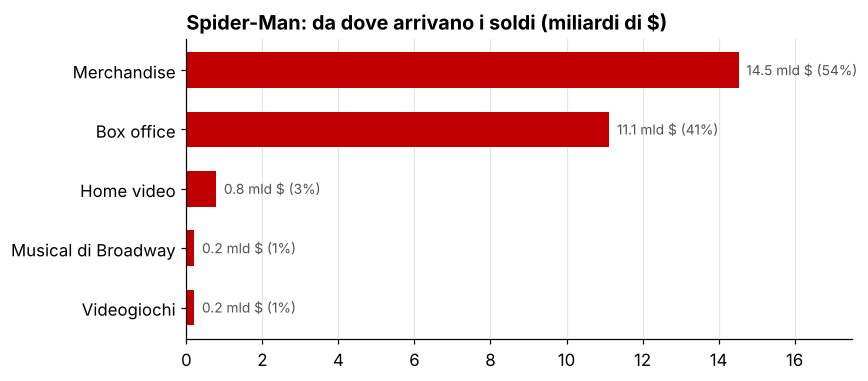

In [2]:
d = inc.sort_values("incasso_milioni_usd")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(d["voce"], d["incasso_milioni_usd"] / 1000, color="#c00000", height=0.6)
for y, (v, q) in enumerate(zip(d["incasso_milioni_usd"] / 1000, d["quota_pct"])):
    ax.text(v + 0.2, y, f"{v:,.1f} mld $ ({q:.0f}%)", va="center", fontsize=9, color="#52514e")
ax.set_title("Spider-Man: da dove arrivano i soldi (miliardi di $)"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, 17.5)
salva("01_incassi_per_voce")

📝 Più della metà arriva dal **merchandise** (giocattoli, vestiti, gadget), il 41% dal **cinema**.

I videogiochi pesano poco **in questa fonte**: la cifra (210 mln $) è vecchia e non include i giochi Insomniac: i due capitoli principali hanno venduto da soli quasi 40 milioni di copie.

## 🎬 2. Come sono andati i film?

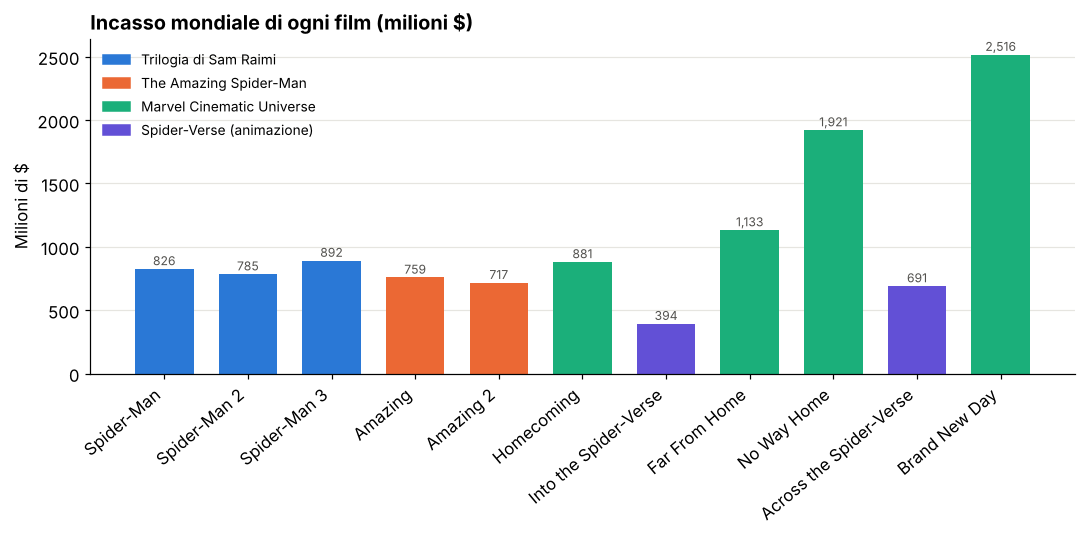

In [3]:
f = film[film["anno"] >= 2002].sort_values("anno")
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(f["titolo"].str.replace("Spider-Man: ", "").str.replace("The Amazing Spider-Man", "Amazing"),
       f["incasso_mondiale_mln"], color=f["saga"].map(SAGA), width=0.7)
for x, (v, a) in enumerate(zip(f["incasso_mondiale_mln"], f["anno"])):
    ax.text(x, v + 30, f"{v:,.0f}", ha="center", fontsize=8, color="#52514e")
ax.set_title("Incasso mondiale di ogni film (milioni $)"); ax.set_ylabel("Milioni di $")
plt.xticks(rotation=40, ha="right"); ax.grid(axis="x", visible=False)
ax.legend(handles=[plt.Rectangle((0,0),1,1,color=c) for s,c in SAGA.items() if s in set(f.saga)],
          labels=[s for s in SAGA if s in set(f.saga)], frameon=False, fontsize=9, loc="upper left")
salva("02_incassi_film")

In [4]:
saghe = (film[film.anno >= 2002].groupby(["saga", "attore"])
         .agg(film=("titolo", "count"), incasso_medio=("incasso_mondiale_mln", "mean"),
              incasso_totale=("incasso_mondiale_mln", "sum"), budget_totale=("budget_mln", "sum"),
              rotten=("rotten_tomatoes_pct", "mean"), metacritic=("metacritic", "mean"),
              cinemascore=("cinemascore_numero", "mean"), biglietti_medi=("biglietti_mondo_mln", "mean")))
saghe["moltiplicatore"] = saghe["incasso_totale"] / saghe["budget_totale"]
saghe.sort_values("incasso_medio", ascending=False).round(1)

,,film,incasso_medio,incasso_totale,budget_totale,rotten,metacritic,cinemascore,biglietti_medi,moltiplicatore
saga,attore,,,,,,,,,
Marvel Cinematic Universe,Tom Holland,4,1612.9,6451.5,760.0,91.5,69.8,4.1,183.8,8.5
Trilogia di Sam Raimi,Tobey Maguire,3,834.0,2502.1,597.0,81.7,71.7,3.6,115.1,4.2
The Amazing Spider-Man,Andrew Garfield,2,737.8,1475.7,480.0,60.5,59.5,3.5,83.2,3.1
Spider-Verse (animazione),Shameik Moore (Miles Morales),2,542.2,1084.4,190.0,96.0,86.5,4.2,72.8,5.7


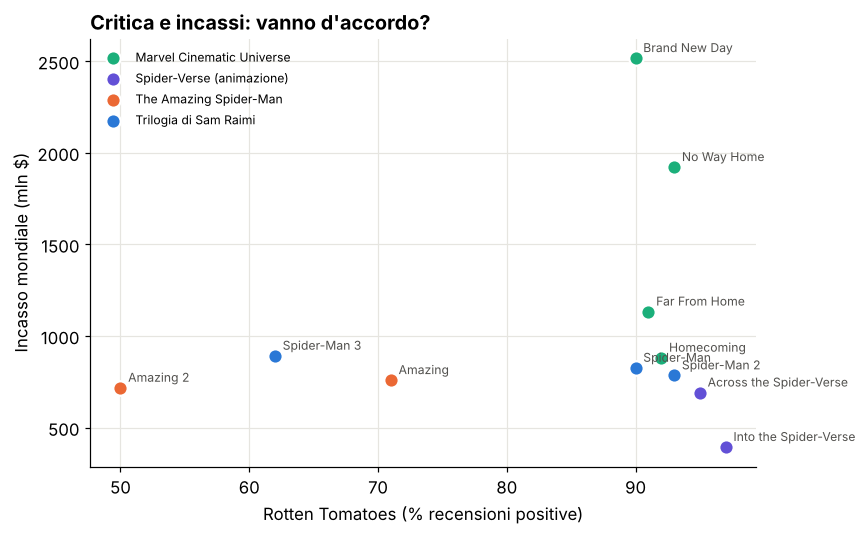

Correlazione di Spearman critica-incassi: -0.25 (p = 0.46, n = 11)


In [5]:
f = film[film.anno >= 2002]
fig, ax = plt.subplots(figsize=(8, 5))
for s, g in f.groupby("saga"):
    ax.scatter(g["rotten_tomatoes_pct"], g["incasso_mondiale_mln"], s=90, color=SAGA[s], label=s, edgecolor="white", linewidth=1.5, zorder=3)
for r in f.itertuples():
    ax.annotate(r.titolo.replace("Spider-Man: ", "").replace("The Amazing Spider-Man", "Amazing"), (r.rotten_tomatoes_pct, r.incasso_mondiale_mln),
                xytext=(5, 4), textcoords="offset points", fontsize=8, color="#52514e")
ax.set_title("Critica e incassi: vanno d'accordo?"); ax.set_xlabel("Rotten Tomatoes (% recensioni positive)"); ax.set_ylabel("Incasso mondiale (mln $)")
ax.legend(frameon=False, fontsize=8, loc="upper left")
salva("03_critica_vs_incassi")
r, p = stats.spearmanr(f["rotten_tomatoes_pct"], f["incasso_mondiale_mln"])
print(f"Correlazione di Spearman critica-incassi: {r:.2f} (p = {p:.2f}, n = {len(f)})")

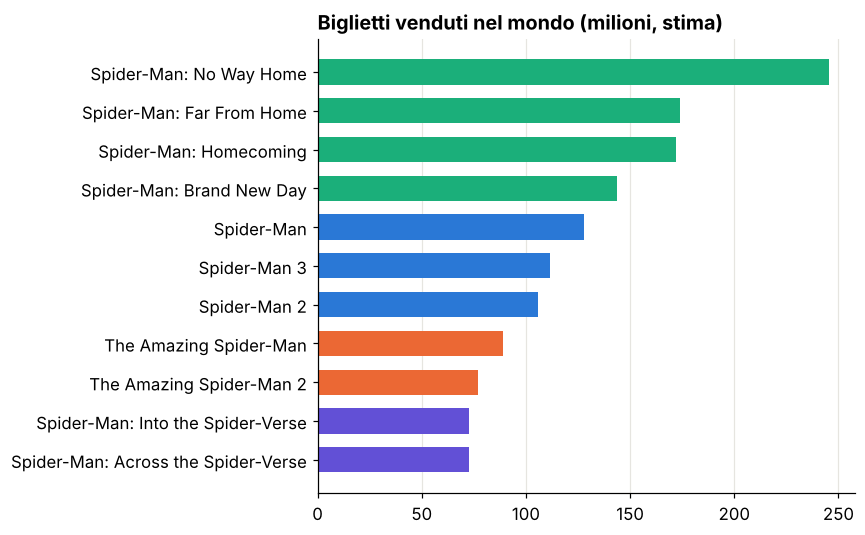

In [6]:
# Biglietti venduti: confronto più giusto tra anni diversi (il prezzo del biglietto cresce col tempo)
b = film.dropna(subset=["biglietti_mondo_mln"]).sort_values("biglietti_mondo_mln")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(b["titolo"], b["biglietti_mondo_mln"], color=b["saga"].map(SAGA), height=0.65)
ax.set_title("Biglietti venduti nel mondo (milioni, stima)"); ax.grid(axis="y", visible=False)
salva("04_biglietti_film")

📝 Contando i **biglietti** (non i dollari), *Spider-Man* del 2002 vale quasi quanto *Far From Home*: l'inflazione gonfia gli incassi recenti.

⚠️ *Brand New Day* (2026) è uscito da poco: biglietti e incassi possono ancora crescere.

## 📈 3. Film e videogiochi fanno cercare il fumetto?

Google Trends, ricerche in tutto il mondo dal 2004.

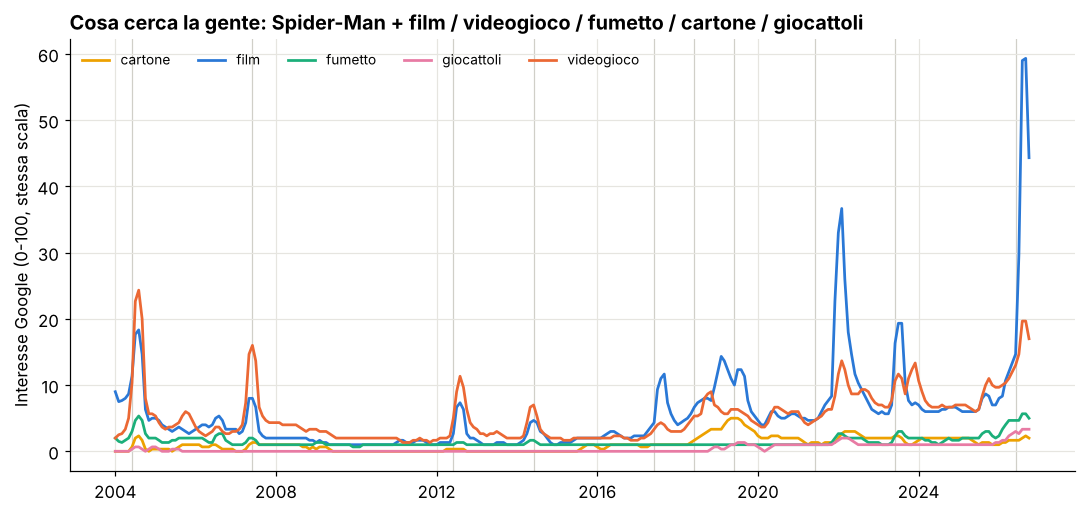

media
film          5.8
videogioco    5.3
fumetto       1.5
cartone       1.1
giocattoli    0.4
Name: interesse, dtype: float64


In [7]:
fig, ax = plt.subplots(figsize=(10, 4.8))
for m, g in tr.groupby("media"):
    ax.plot(g["mese"], g["interesse"].rolling(3, min_periods=1).mean(), color=MEDIA[m], linewidth=1.8, label=m)
for r in film[film.anno >= 2004].itertuples():
    ax.axvline(pd.Timestamp(f"{r.anno}-06-01"), color="#d0cfc8", linewidth=0.8, zorder=0)
ax.set_title("Cosa cerca la gente: Spider-Man + film / videogioco / fumetto / cartone / giocattoli")
ax.set_ylabel("Interesse Google (0-100, stessa scala)"); ax.legend(frameon=False, ncol=5, fontsize=9, loc="upper left")
salva("05_trends_per_media")
print(tr.groupby("media")["interesse"].mean().sort_values(ascending=False).round(1))

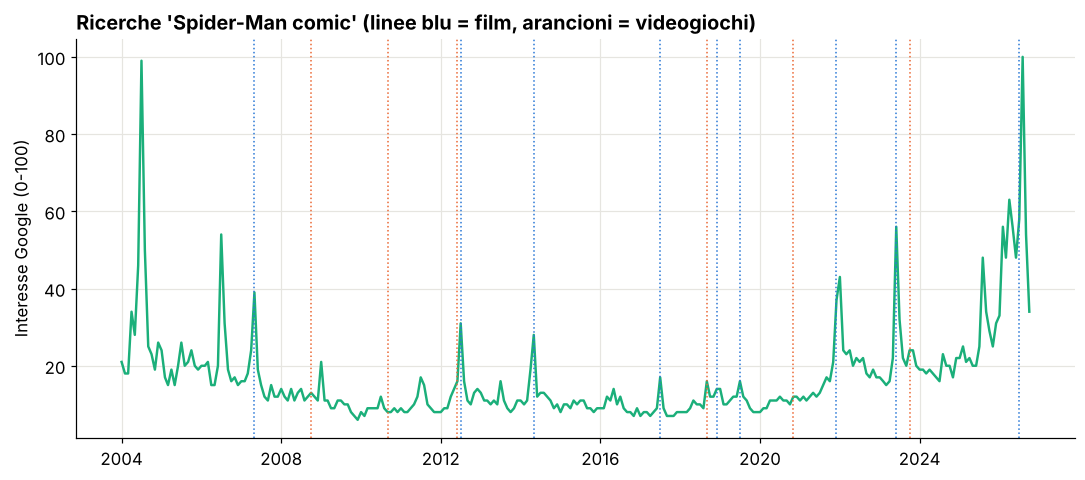

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(trf["mese"], trf["interesse"], color=MEDIA["fumetto"], linewidth=1.6)
for r in ev.itertuples():
    m = pd.Timestamp(r.mese_uscita)
    ax.axvline(m, color="#2a78d6" if r.tipo == "Film" else "#eb6834", linewidth=1, linestyle=":")
ax.set_title("Ricerche 'Spider-Man comic' (linee blu = film, arancioni = videogiochi)")
ax.set_ylabel("Interesse Google (0-100)")
salva("06_trends_fumetto_uscite")

In [9]:
e = ev.copy()
e["picco"] = e["fumetto_mese_uscita"] / e["fumetto_prima"]
display(e[["tipo", "titolo", "mese_uscita", "fumetto_prima", "fumetto_mese_uscita", "fumetto_dopo", "picco", "variazione_pct"]].round(2))
print(e.groupby("tipo").agg(uscite=("titolo", "count"), picco_medio=("picco", "mean"), variazione_media=("variazione_pct", "mean"),
                            con_crescita=("differenza", lambda s: (s > 0).sum())).round(2))
w = stats.wilcoxon(e.loc[e.tipo == "Film", "fumetto_mese_uscita"], e.loc[e.tipo == "Film", "fumetto_prima"])
print(f"\nFilm – mese di uscita contro 6 mesi prima: Wilcoxon p = {w.pvalue:.3f}")

,tipo,titolo,mese_uscita,fumetto_prima,fumetto_mese_uscita,fumetto_dopo,picco,variazione_pct
0,Film,Spider-Man 3,2007-05-01,17.67,39.0,14.00,2.21,-20.8
1,Film,The Amazing Spider-Man,2012-07-01,11.33,31.0,12.83,2.74,13.2
2,Film,The Amazing Spider-Man 2,2014-05-01,11.83,28.0,11.67,2.37,-1.4
3,Film,Spider-Man: Homecoming,2017-07-01,7.83,17.0,7.67,2.17,-2.0
4,Film,Spider-Man: Into the Spider-Verse,2018-12-01,11.50,14.0,11.50,1.22,0.0
5,Film,Spider-Man: Far From Home,2019-07-01,11.50,16.0,9.33,1.39,-18.9
6,Film,Spider-Man: No Way Home,2021-12-01,15.67,37.0,26.00,2.36,65.9
7,Film,Spider-Man: Across the Spider-Verse,2023-06-01,17.17,56.0,23.67,3.26,37.9
8,Film,Spider-Man: Brand New Day,2026-07-01,50.67,58.0,62.67,1.14,23.7
9,Videogioco,Marvel's Spider-Man,2018-09-01,9.50,16.0,12.00,1.68,26.3


            uscite  picco_medio  variazione_media  con_crescita
tipo                                                           
Film             9         2.10             10.84             4
Videogioco       6         1.19              8.43             3

Film – mese di uscita contro 6 mesi prima: Wilcoxon p = 0.004


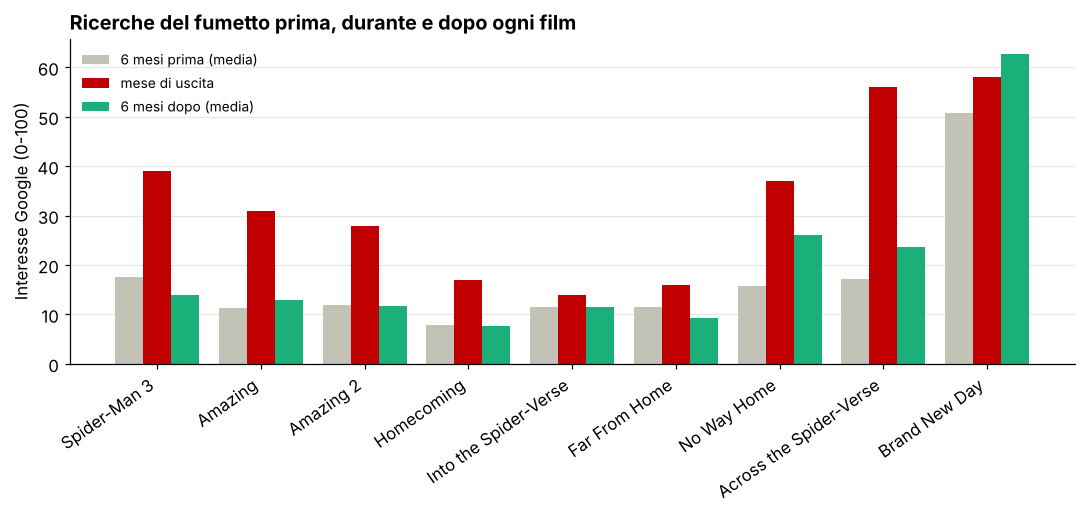

In [10]:
f = e[e.tipo == "Film"].sort_values("mese_uscita")
x = np.arange(len(f)); w = 0.27
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(x - w, f["fumetto_prima"], w, color="#c3c2b7", label="6 mesi prima (media)")
ax.bar(x, f["fumetto_mese_uscita"], w, color="#c00000", label="mese di uscita")
ax.bar(x + w, f["fumetto_dopo"], w, color="#1baf7a", label="6 mesi dopo (media)")
ax.set_xticks(x); ax.set_xticklabels(f["titolo"].str.replace("Spider-Man: ", "").str.replace("The Amazing Spider-Man", "Amazing"), rotation=35, ha="right")
ax.set_title("Ricerche del fumetto prima, durante e dopo ogni film"); ax.set_ylabel("Interesse Google (0-100)")
ax.legend(frameon=False, fontsize=9); ax.grid(axis="x", visible=False)
salva("07_prima_durante_dopo")

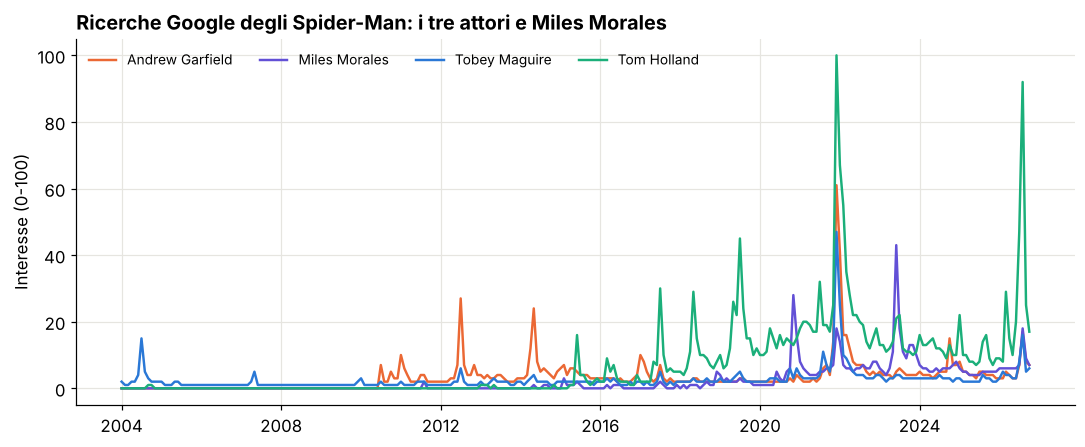

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.2))
col = {"tobey_maguire": "#2a78d6", "andrew_garfield": "#eb6834", "tom_holland": "#1baf7a", "miles_morales": "#6250d6"}
for p, g in tra.groupby("persona"):
    ax.plot(g["mese"], g["interesse"], color=col[p], linewidth=1.6, label=p.replace("_", " ").title())
ax.set_title("Ricerche Google degli Spider-Man: i tre attori e Miles Morales"); ax.set_ylabel("Interesse (0-100)")
ax.legend(frameon=False, ncol=4, fontsize=9)
salva("08_trends_attori")

## 🎮 4. Spider-Man nei videogiochi

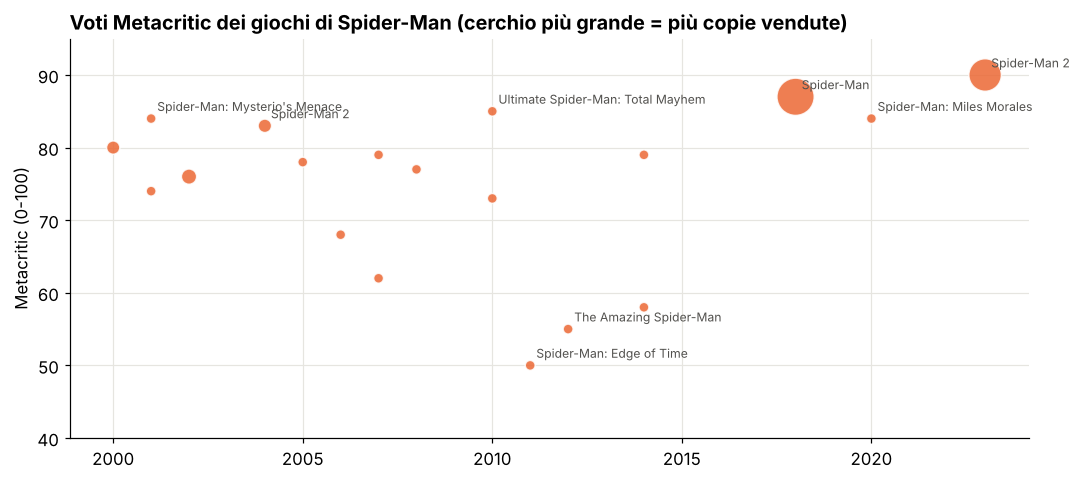

          giochi  metacritic  piattaforme
decennio                                 
1980           4         NaN          4.2
1990          15         NaN          1.9
2000          12        76.1          4.4
2010           8        69.6          5.1
2020           2        87.0          2.5


In [12]:
g = giochi.copy()
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.scatter(g["anno"], g["metacritic"], s=g["copie_milioni"].fillna(0.5) * 25 + 30, color="#eb6834", alpha=0.85, edgecolor="white", zorder=3)
for r in g.dropna(subset=["metacritic"]).itertuples():
    if r.metacritic >= 83 or r.metacritic <= 55:
        ax.annotate(r.titolo.replace("Marvel's ", ""), (r.anno, r.metacritic), xytext=(4, 5), textcoords="offset points", fontsize=8, color="#52514e")
ax.set_title("Voti Metacritic dei giochi di Spider-Man (cerchio più grande = più copie vendute)")
ax.set_ylabel("Metacritic (0-100)"); ax.set_ylim(40, 95)
salva("09_videogiochi_voti")
print(g.groupby("decennio").agg(giochi=("titolo", "count"), metacritic=("metacritic", "mean"), piattaforme=("n_piattaforme", "mean")).round(1))

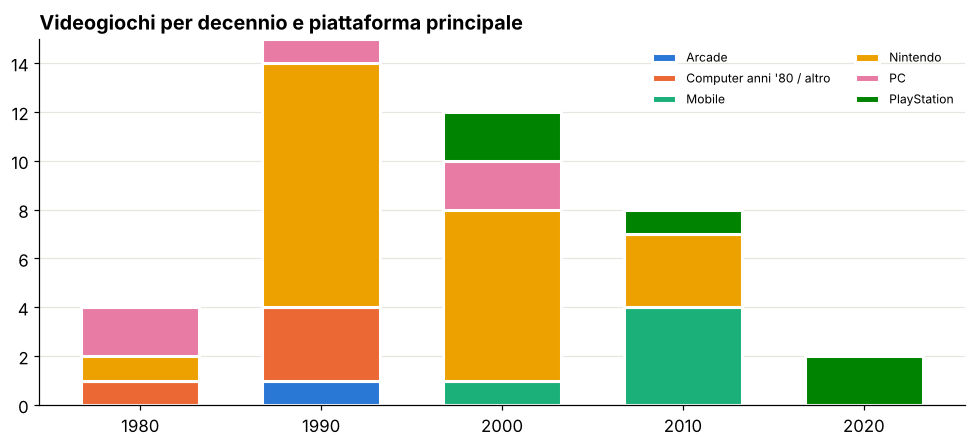

In [13]:
p = g.pivot_table(index="decennio", columns="famiglia_principale", values="id_gioco", aggfunc="count", fill_value=0)
colori = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
fig, ax = plt.subplots(figsize=(9, 4.2)); base = np.zeros(len(p))
for i, c in enumerate(p.columns):
    ax.bar(p.index.astype(str), p[c], bottom=base, color=colori[i % 7], label=c, width=0.65, edgecolor="white", linewidth=2); base += p[c].values
ax.set_title("Videogiochi per decennio e piattaforma principale"); ax.legend(frameon=False, fontsize=8, ncol=2)
ax.grid(axis="x", visible=False)
salva("10_videogiochi_piattaforme")

## 📺📚 Serie TV e fumetti

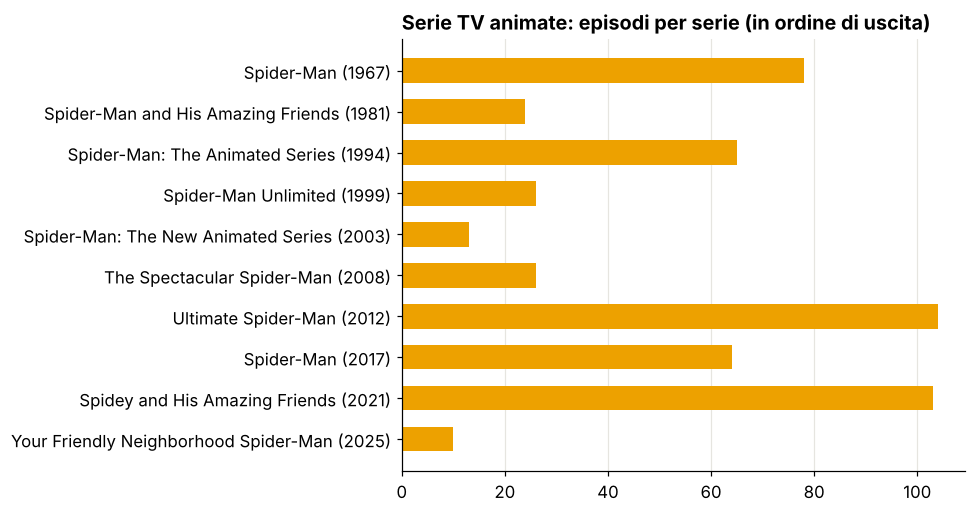

In [14]:
s = serie.groupby("serie").agg(episodi=("episodi", "sum"), inizio=("anno_inizio", "min")).sort_values("inizio")
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(s.index, s["episodi"], color="#eda100", height=0.6)
ax.invert_yaxis(); ax.set_title("Serie TV animate: episodi per serie (in ordine di uscita)"); ax.grid(axis="y", visible=False)
salva("11_serie_tv")

media,Film,Fumetto (nuova testata),Serie TV,Videogioco
decennio,,,,
1960,0,5,1,0
1970,1,11,0,0
1980,0,12,1,4
1990,0,30,2,15
2000,3,37,2,12
2010,5,63,2,8
2020,3,27,2,2


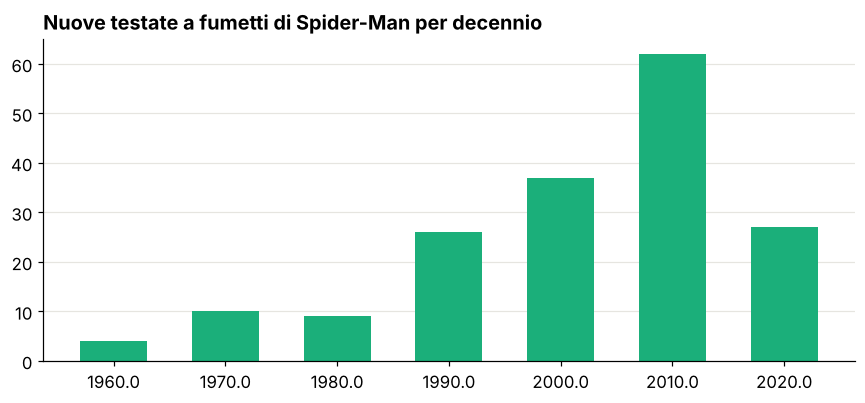

Numeri pubblicati per The Amazing Spider-Man (tutti i volumi): 926


In [15]:
t = tl.pivot_table(index="decennio", columns="media", values="titolo", aggfunc="count", fill_value=0)
display(t)
c = fum[fum["tipo"].isin(["Serie principali", "Altre continuità"])].groupby("decennio")["id_testata"].count()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(c.index.astype(str), c.values, color="#1baf7a", width=0.6)
ax.set_title("Nuove testate a fumetti di Spider-Man per decennio"); ax.grid(axis="x", visible=False)
salva("12_fumetti_nuove_testate")
print("Numeri pubblicati per The Amazing Spider-Man (tutti i volumi):",
      int(fum.loc[fum.titolo == "The Amazing Spider-Man", "numeri_pubblicati"].sum()))

## 🦹 5. I personaggi del suo mondo

Apparizioni nei fumetti Marvel (FiveThirtyEight, dati 2014).

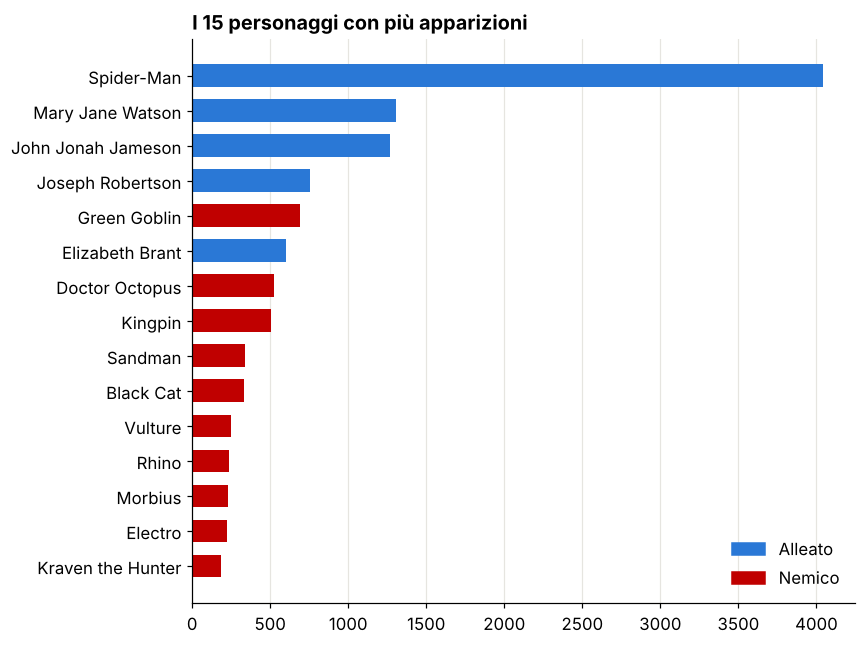

Nemici nati negli anni '60: 31 su 93
numero_debutto_amazing
Successivi           60.0
Classici (#1-50)    143.0
Name: apparizioni, dtype: float64


In [16]:
p = pers.dropna(subset=["apparizioni"]).nlargest(15, "apparizioni").iloc[::-1]
col = p["ruolo"].map({"Nemico": "#c00000", "Protagonista/Alleato": "#2a78d6"})
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(p["personaggio"], p["apparizioni"], color=col, height=0.65)
ax.set_title("I 15 personaggi con più apparizioni"); ax.grid(axis="y", visible=False)
ax.legend(handles=[plt.Rectangle((0,0),1,1,color=c) for c in ["#2a78d6", "#c00000"]], labels=["Alleato", "Nemico"], frameon=False, loc="lower right")
salva("13_personaggi")
n = pers[pers.ruolo == "Nemico"]
print("Nemici nati negli anni '60:", (n["anno_debutto"] < 1970).sum(), "su", n["anno_debutto"].notna().sum())
print(n.groupby(n["numero_debutto_amazing"] <= 50)["apparizioni"].mean().round(0).rename({True: "Classici (#1-50)", False: "Successivi"}))

## ✅ Conclusioni e ⚠️ limiti

Le risposte sono nel file **CONCLUSIONI.md** in questa cartella.

📌 Copie vendute note solo per 5 videogiochi. 📌 Nessun dato pubblico sulle vendite dei singoli fumetti.
📌 Google Trends misura ricerche, non vendite. 📌 Brand New Day (2026) è ancora recente. 📌 Personaggi aggiornati al 2014.